In [78]:
# import hst aperture for wfc3 from hayden's code

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 10,
})

plt.rcParams["figure.dpi"] = 300
# fig_width = 379.41753 / 72.27 # = 5.25
fig_width = 5.25

/Library/TeX/texbin/latex


In [79]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        detected_w = self.filt_weights * spec_w

        self.flux = detected_w.sum()
        self.weights = detected_w / self.flux

    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [80]:
# spectrum interpolation
import dLux as dl
import jax
import jax.numpy as np
from jax import vmap


# -------------------------------------------------
# 0. A tiny monochromatic spectrum object
# -------------------------------------------------
# This reuses your existing CombinedBasisSpectrum machinery with 1 wavelength.
def monochromatic_spectrum(lam):
    return CombinedBasisSpectrum(
        wavels=np.array([lam]),
        filt_weights=np.array([1.0]),
        basis_weights=np.array([1.0]),
        basis=np.array([[1.0]]),
    )


# -------------------------------------------------
# 1. Pre-detector optical image at one wavelength
# -------------------------------------------------
def optics_image_lambda(lam, instrument):
    """
    Returns the optical image before the detector, while preserving the current
    source object (including source.position).

    Only the source spectrum is replaced by a monochromatic spectrum.
    """
    mono_spec = monochromatic_spectrum(lam)

    source = instrument.get("source")
    source = source.set("spectrum", mono_spec)
    source = source.set("flux", 1.0)  # unit source flux for basis image

    optics = instrument.optics
    # In dLux this is typically the source propagated through the optics.
    # If your local version uses a slightly different call, this is the only
    # line you should need to swap.
    return source.model(optics)


# -------------------------------------------------
# 2. Optical image and d/dlambda of optical image
# -------------------------------------------------
def optics_image_and_dlambda(lam, instrument):
    f = lambda x: optics_image_lambda(x, instrument)
    img = f(lam)
    dimg_dlam = jax.jacfwd(f)(lam)
    return img, dimg_dlam


# -------------------------------------------------
# 3. Evaluate those on the coarse wavelength grid
# -------------------------------------------------
def coarse_optics_images_and_derivs(wavelengths_coarse, instrument):
    imgs, dimgs = vmap(
        lambda lam: optics_image_and_dlambda(lam, instrument)
    )(wavelengths_coarse)

    # imgs.shape  = (Ncoarse, nx, ny)
    # dimgs.shape = (Ncoarse, nx, ny)
    return imgs, dimgs


# -------------------------------------------------
# 4. Dense fine-grid weights -> Hermite node coefficients
# -------------------------------------------------
def hermite_node_coeffs(wavelengths_fine, dense_weights, wavelengths_coarse):
    """
    For
        sum_j dense_weights[j] * O(lambda_fine[j]),
    compute coefficients multiplying coarse-node optical images and
    their wavelength derivatives under piecewise cubic Hermite interpolation.
    """
    wavelengths_fine = np.asarray(wavelengths_fine, dtype=float)
    dense_weights = np.asarray(dense_weights, dtype=float)
    wavelengths_coarse = np.asarray(wavelengths_coarse, dtype=float)

    n_coarse = wavelengths_coarse.size

    idx = np.searchsorted(wavelengths_coarse, wavelengths_fine, side="right") - 1
    idx = np.clip(idx, 0, n_coarse - 2)

    lam0 = wavelengths_coarse[idx]
    lam1 = wavelengths_coarse[idx + 1]
    dlam = lam1 - lam0

    t = (wavelengths_fine - lam0) / dlam

    h00 =  2*t**3 - 3*t**2 + 1
    h10 =      t**3 - 2*t**2 + t
    h01 = -2*t**3 + 3*t**2
    h11 =      t**3 -     t**2

    coeff_val = np.zeros(n_coarse, dtype=dense_weights.dtype)
    coeff_der = np.zeros(n_coarse, dtype=dense_weights.dtype)

    coeff_val = coeff_val.at[idx].add(dense_weights * h00)
    coeff_val = coeff_val.at[idx + 1].add(dense_weights * h01)

    coeff_der = coeff_der.at[idx].add(dense_weights * (dlam * h10))
    coeff_der = coeff_der.at[idx + 1].add(dense_weights * (dlam * h11))

    return coeff_val, coeff_der


# -------------------------------------------------
# 5. Apply detector once at the end
# -------------------------------------------------
def apply_detector(optical_image, instrument):
    detector = instrument.detector
    pixel_scale = instrument.optics.psf_pixel_scale
    oversample = instrument.optics.oversample
    pscale = pixel_scale/oversample
    psf = dl.PSF(optical_image, pscale)

    # If your detector object uses a slightly different method name,
    # this is the other line you may need to swap.
    return detector.model(psf)


# -------------------------------------------------
# 6. Hermite forward model: optics interpolation first, detector last
# -------------------------------------------------
def model_psf_hermite(spectrum, instrument, wavelengths_coarse):
    """
    spectrum:
        Same meaning as in your current model_psf. If source.spectrum is a
        CombinedBasisSpectrum, this can be the basis coefficients.

    instrument:
        Current Telescope(optics, source, detector). Source position etc. are kept.

    wavelengths_coarse:
        Coarse wavelength nodes where the optical image and d/dlambda are evaluated.
    """
    old_spec = instrument.get("source.spectrum")

    # reconstruct dense fine-grid spectrum from basis coefficients
    spec_w = np.maximum(old_spec.basis_vects @ spectrum, eps) # non log
    # spec_w = 10 ** (old_spec.basis_vects @ spectrum) # log

    # dense per-wavelength weights before normalisation
    dense_weights = old_spec.filt_weights * spec_w

    # same overall normalisation convention as your original model_psf
    flux_prefactor = spec_w.sum() / dense_weights.sum()

    # scalar coefficients multiplying coarse-node optical images/derivatives
    coeff_val, coeff_der = hermite_node_coeffs(
        wavelengths_fine=old_spec.wavelengths,
        dense_weights=dense_weights,
        wavelengths_coarse=wavelengths_coarse,
    )

    # evaluate pre-detector optical images and wavelength derivatives
    imgs, dimgs = coarse_optics_images_and_derivs(wavelengths_coarse, instrument)

    # reconstruct dense polychromatic optical image
    optical_image = (
        np.tensordot(coeff_val, imgs, axes=(0, 0)) +
        np.tensordot(coeff_der, dimgs, axes=(0, 0))
    )

    optical_image = flux_prefactor * optical_image

    # detector acts once, at the end
    return apply_detector(optical_image, instrument)


# normal model psf
def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    
    return telescope.model()

In [81]:
class HSTMainAperture(dl.CompoundAperture):
    softening : float
    def __init__(self, transformation=dl.CoordTransform(rotation=np.pi/4), softening=0.25):
        self.normalise = True
        self.transformation = transformation
        self.softening = softening
        self.apertures = {
            "mirror" : dl.CircularAperture(
                radius = 1.2,
                softening=self.softening,
                #normalise=True
            ),
            "spider" : dl.Spider(
                width = 0.022*1.2,#0.038*1.2,
                angles = np.asarray([0, 90, 180, 270]),
                softening=self.softening,
            ),
            "secondary" : dl.CircularAperture(
                radius = 0.330*1.2,
                occulting = True,
                softening = self.softening
            ),
            "pad_1" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (0.8921*1.2, 0),
                ),
                softening = self.softening
            ),
            "pad_2" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (-0.4615*1.2, 0.7555*1.2),
                ),
                softening = self.softening
            ),
            "pad_3" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (-0.4564*1.2, -0.7606*1.2),
                ),
                softening=self.softening
            )
        }

class WFC3Optics(dl.AngularOpticalSystem):
    def __init__(self, wf_npixels, psf_npixels, psf_pixel_scale, oversample):
        super().__init__(
            wf_npixels,
            2.4,
            [
                    ("main_aperture",HSTMainAperture(transformation=dl.CoordTransform(rotation=np.pi/4), softening=2))
            ],
            psf_npixels,
            psf_pixel_scale,
            oversample
        )

from jax import lax
from dLux.psfs import PSF

class MemorySafeWFC3Optics(WFC3Optics):
    def propagate(
        self,
        wavelengths,
        offset=None,
        weights=None,
        return_wf=False,
        return_psf=False,
    ):
        if return_wf:
            raise NotImplementedError(
                "Memory-safe propagate does not return per-wavelength wavefronts, "
                "because that would require storing the full wavelength stack."
            )

        if return_wf and return_psf:
            raise ValueError("Cannot return both return_wf=True and return_psf=True.")

        wavelengths = np.atleast_1d(wavelengths)

        if weights is None:
            weights = np.ones_like(wavelengths) / len(wavelengths)
        else:
            weights = np.atleast_1d(weights)

        if offset is None:
            offset = np.zeros(2)
        else:
            offset = np.asarray(offset)

        if weights.shape != wavelengths.shape:
            raise ValueError(
                f"wavelengths and weights must have the same shape, got "
                f"{wavelengths.shape} and {weights.shape}."
            )

        # Make one monochromatic PSF to initialise the accumulator.
        # Multiply by zero so this contributes nothing.
        psf0 = np.zeros_like(
            self.propagate_mono(wavelengths[0], offset, return_wf=False)
        )

        def step(psf_acc, x):
            wavelength, weight = x

            # dLux's original code multiplies phasor by sqrt(weight),
            # then forms intensity, equivalent to weight * psf.
            psf_i = self.propagate_mono(
                wavelength,
                offset,
                return_wf=False,
            )

            return psf_acc + weight * psf_i, None

        psf, _ = lax.scan(step, psf0, (wavelengths, weights))

        if return_psf:
            # For AngularOpticalSystem this is approximately the final image pixel scale.
            # dLux normally uses wf.pixel_scale.mean(); for your purposes this is fine
            # unless you rely on the PSF object's pixel_scale very carefully.
            pixel_scale = self.psf_pixel_scale / self.oversample
            return PSF(psf, pixel_scale)

        return psf

In [82]:
import numpy as onp
def trim_to_regular_grid(wave, throughput, rtol=1e-3, min_run=10):
    """
    Trim irregularly spaced wavelength points from the beginning/end,
    keeping the largest central region with approximately constant spacing.

    Parameters
    ----------
    wave : array
        Wavelength array.
    throughput : array
        Throughput array.
    rtol : float
        Relative tolerance for accepting a wavelength spacing as regular.
        Try 1e-3, 1e-4, or 1e-2 depending on the file.
    min_run : int
        Minimum number of consecutive good spacings required near edges.

    Returns
    -------
    wave_trim : array
    throughput_trim : array
    good_spacing : float
        Estimated regular wavelength spacing.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    dw = onp.diff(wave)

    # Estimate regular grid spacing from the median
    dw0 = onp.median(dw)

    good = onp.isclose(dw, dw0, rtol=rtol, atol=0.0)

    # Find first place where we get a stable run of good spacings
    start = 0
    for i in range(len(good) - min_run + 1):
        if onp.all(good[i:i + min_run]):
            start = i
            break

    # Find last place where we get a stable run of good spacings
    end = len(wave)
    for i in range(len(good) - min_run, -1, -1):
        if onp.all(good[i:i + min_run]):
            end = i + min_run + 1
            break

    return wave[start:end], throughput[start:end], dw0


def bin_filter_midpoints(wave, throughput, n_bins):
    """
    Bin a throughput curve into n_bins equal-width wavelength bins.

    Returns
    -------
    centres : array
        Midpoint wavelength of each bin.
    mean_throughput : array
        Average throughput in each bin.
    edges : array
        Bin edges.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    edges = onp.linspace(wave.min(), wave.max(), n_bins + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    mean_throughput = onp.zeros(n_bins)

    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]

        mask = (wave >= lo) & (wave <= hi)

        # Include bin edges by interpolation so partial bins behave correctly
        w = onp.concatenate([[lo], wave[mask], [hi]])
        t = onp.interp(w, wave, throughput)

        # Remove duplicated points
        w, unique = onp.unique(w, return_index=True)
        t = t[unique]

        mean_throughput[i] = onp.trapezoid(t, w) / (hi - lo)

    return centres, mean_throughput, edges

In [97]:
# extracting the relevant bandpass
# use uvis2 for a 512 subarray,
# i think 606w, 438w, and 814w cover a decent range for imaging!
# so we do recoverable modes and spectral resolution for those, given a single exposure and multiple exposures
# upto say 10 exposures should be more than enough.
# 1 figure for the single exposure case, another figure for the multiple exposure case. legended for each.
# I hope this fits the idea of optica paper... doing specific astronomy examples might make people cringe a little
# then we'd do JUST NIrcam. nobody uses the wide filter on ami and the medium has barely any juice to squeeze
# the juice to squeeze on ami spectra probs coming from outer dithers.. which is a separate paper.
# nircam filters: short channel F150W2 (big), F200W.
# long channel: F322W2 (big), F444W.
# and that should be enough.
# looks like I'll be using the sub400p subarray as the most reasonable one.
path = "UVIS/wfc3_uvis2_f814w.txt"  
arr = onp.loadtxt(path)
wave_A = arr[:, 0]      
throughput = arr[:, 1]    

wave_m = wave_A * 1e-10

# truncating to remove zeros

through_thresh = 1e-3*np.max(throughput)

waves_trim = wave_m[throughput>through_thresh]
throughput_trim = throughput[throughput>through_thresh]

# waves_trim = wave_m[np.argmax(throughput>0)-1:]
# throughput_trim = throughput[np.argmax(throughput>0)-1:]

# waves_trim, throughput_trim, _ = trim_to_regular_grid(waves_trim, throughput_trim)

waves_bin, throughput_bin, _ = bin_filter_midpoints(waves_trim, throughput_trim, 101)

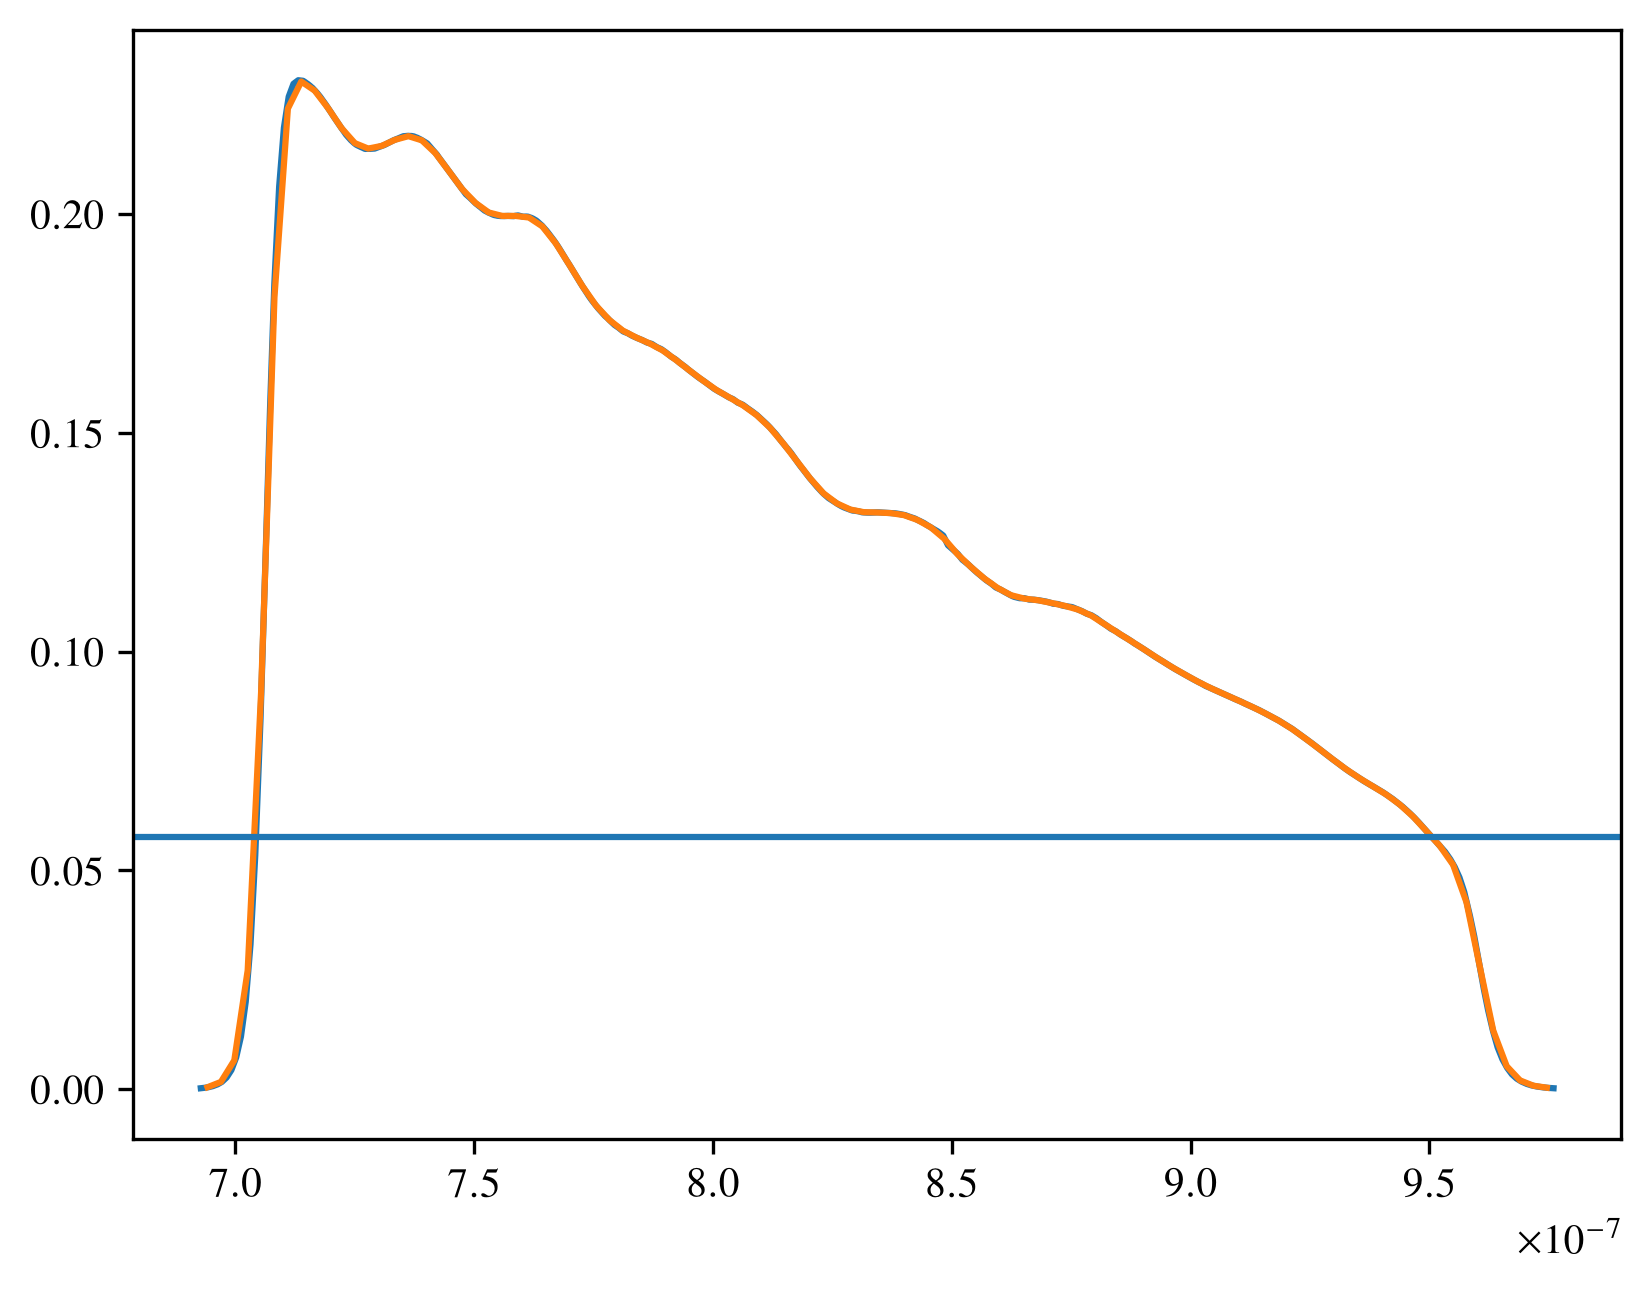

In [98]:
plt.plot(waves_trim, throughput_trim)
plt.plot(waves_bin, throughput_bin)
plt.axhline(0.25*np.max(throughput_trim))
plt.show()

In [99]:
# constructing the source
N = throughput_bin.size
# throughput_bin = np.ones(N)

spectrum_model = CombinedBasisSpectrum(waves_bin, throughput_bin, np.ones(N), np.eye(N))

source_model = dl.PointSource(
    spectrum=spectrum_model
)

# for psfnpix = 512, need at least 1024 wfnpix
wf_npix = 1024
psf_npix = 512
diameter = 2.4
oversample = 4

optics = MemorySafeWFC3Optics(wf_npixels=wf_npix, psf_npixels=psf_npix, psf_pixel_scale=0.039, oversample=oversample)
optics_s = MemorySafeWFC3Optics(wf_npixels=wf_npix, psf_npixels=2, psf_pixel_scale=0.039, oversample=oversample)

detector = dl.LayeredDetector([
    (
        'downsample',
        dl.detector_layers.Downsample(kernel_size=oversample)
    )
])

instrument = dl.Telescope(optics, source_model, detector)

instrument_s = dl.Telescope(optics_s, source_model, detector)

# maximum well depth: 63,000 e. 
flux = 1e6
injected_spectrum = np.ones(N)/N * flux # flat injected spectrum, same flux

# coarse wavelengths:
n_coarse = N #200
wlmin = np.min(waves_bin)
wlmax = np.max(waves_bin)
wavelengths_coarse = np.linspace(wlmin, wlmax, n_coarse)

# img_hermite = model_psf_hermite(injected_spectrum, instrument, wavelengths_coarse)
img_s = model_psf(injected_spectrum, instrument_s)

# getting the proper flux
flux_ratio = 63000/np.max(img_s)
injected_spectrum *= flux_ratio

img_full = model_psf(injected_spectrum, instrument)

In [100]:
np.max(img_full)

Array(63000., dtype=float64)

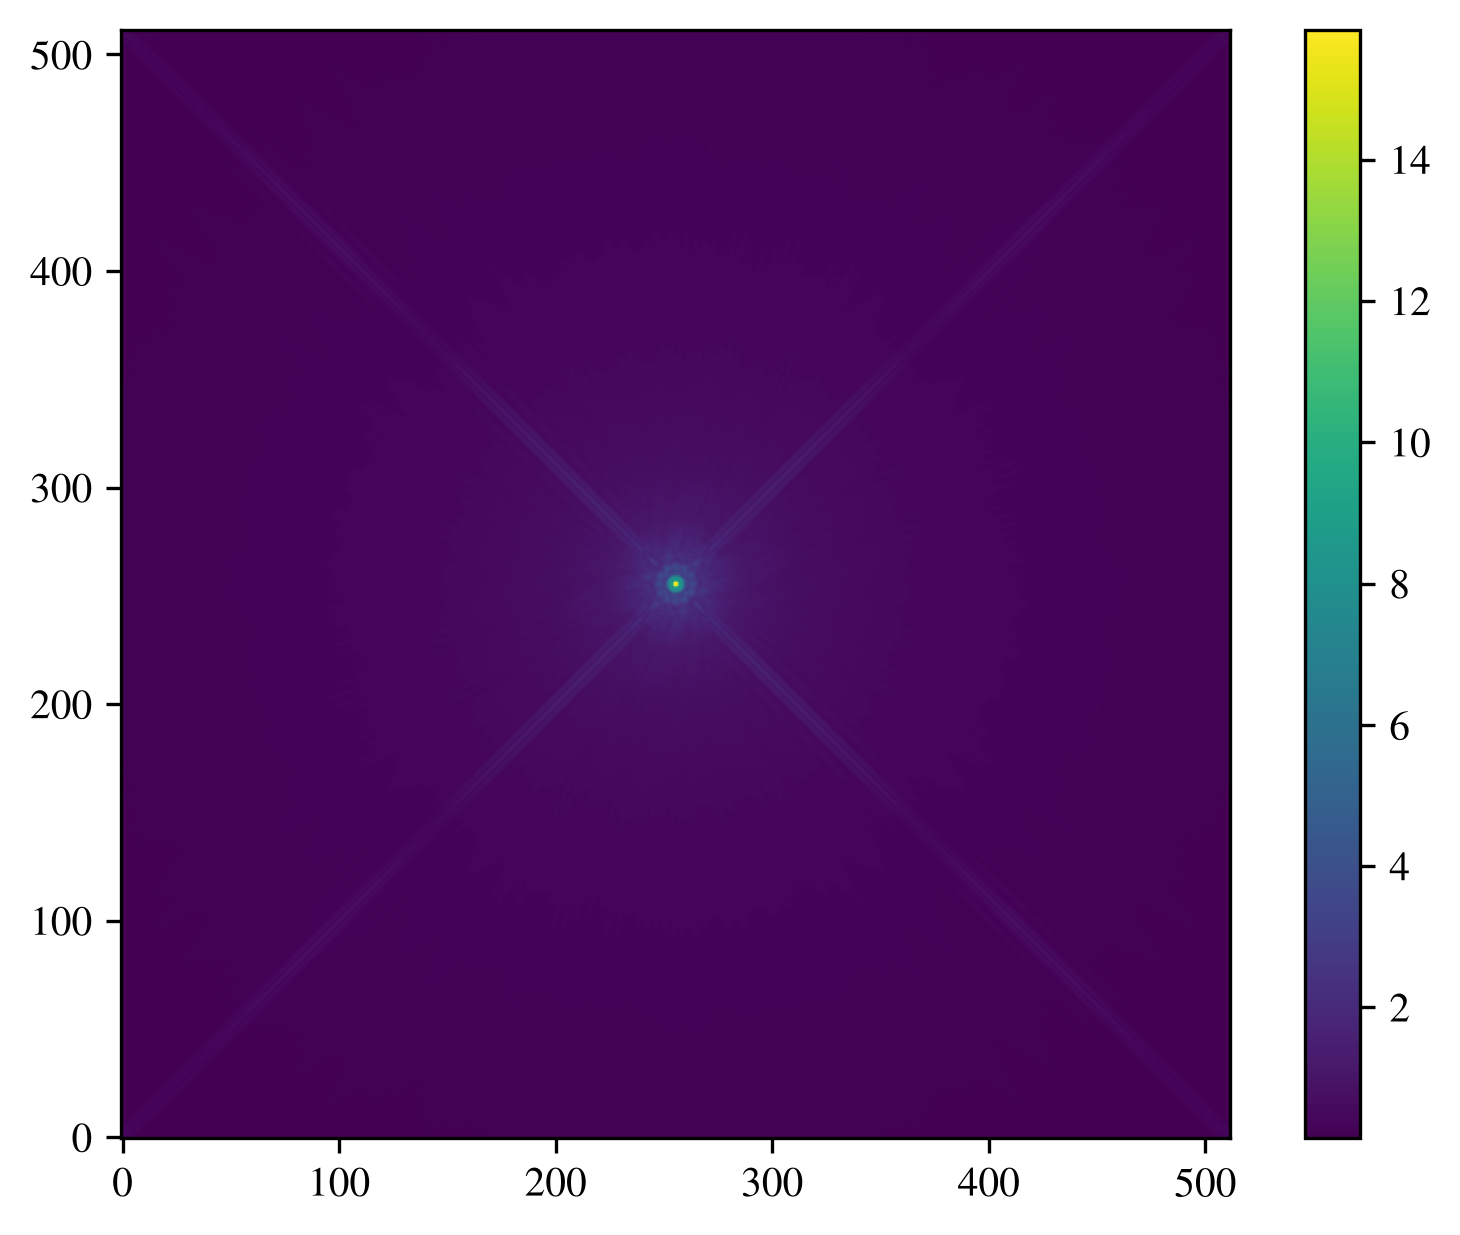

In [101]:
plt.imshow((img_full)**0.25)
plt.colorbar()
plt.show()

In [102]:
from zodiax.diffops import hessian
import jax.scipy as jsp

def loss_fn(params, model, data):
    spectrum = params['spectrum']
    # img = model_psf_hermite(spectrum, model, wavelengths_coarse)
    img = model_psf(spectrum, model)
    # loss = -poisson_loglike_gamma(data, img).sum()
    # for correct gaussian approximation, must use the data as the error term
    sigma_r = 3.0 # 3.0 electrons readout nosie
    loss = -normal_logpdf(data, img, np.sqrt(data+sigma_r**2)).sum()
    return loss

params = {
    "spectrum": injected_spectrum
}

# total derangement incoming
f = lambda params: loss_fn(params, instrument, img_full)

H, unflatten = hessian(f, params)

In [103]:
eigvals, eigvecs = np.linalg.eigh(H)

idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]
mode_spectra = np.fft.rfft(eigvecs, axis=0)

# Optional sign convention
for i in range(eigvecs.shape[0]):
    eigvecs = eigvecs.at[:, i].mul(np.sign(np.mean(eigvecs[:2, i])))

a = eigvecs.T @ injected_spectrum

relstd = 1 / (np.abs(a[0]) * np.sqrt(eigvals))

# eigvals_all = []
# a0s_all = []

eigvals_all.append(eigvals)
a0s_all.append(a[0])

In [ ]:
# np.save('eigvecs_606w.npy', eigvecs) # save some eigvecs

In [104]:
eigvals_all = np.asarray(eigvals_all)
a0s_all = np.asarray(a0s_all)
np.save('wfc3_eigvals.npy', eigvals_all)
np.save('wfc3_a0s.npy', a0s_all)

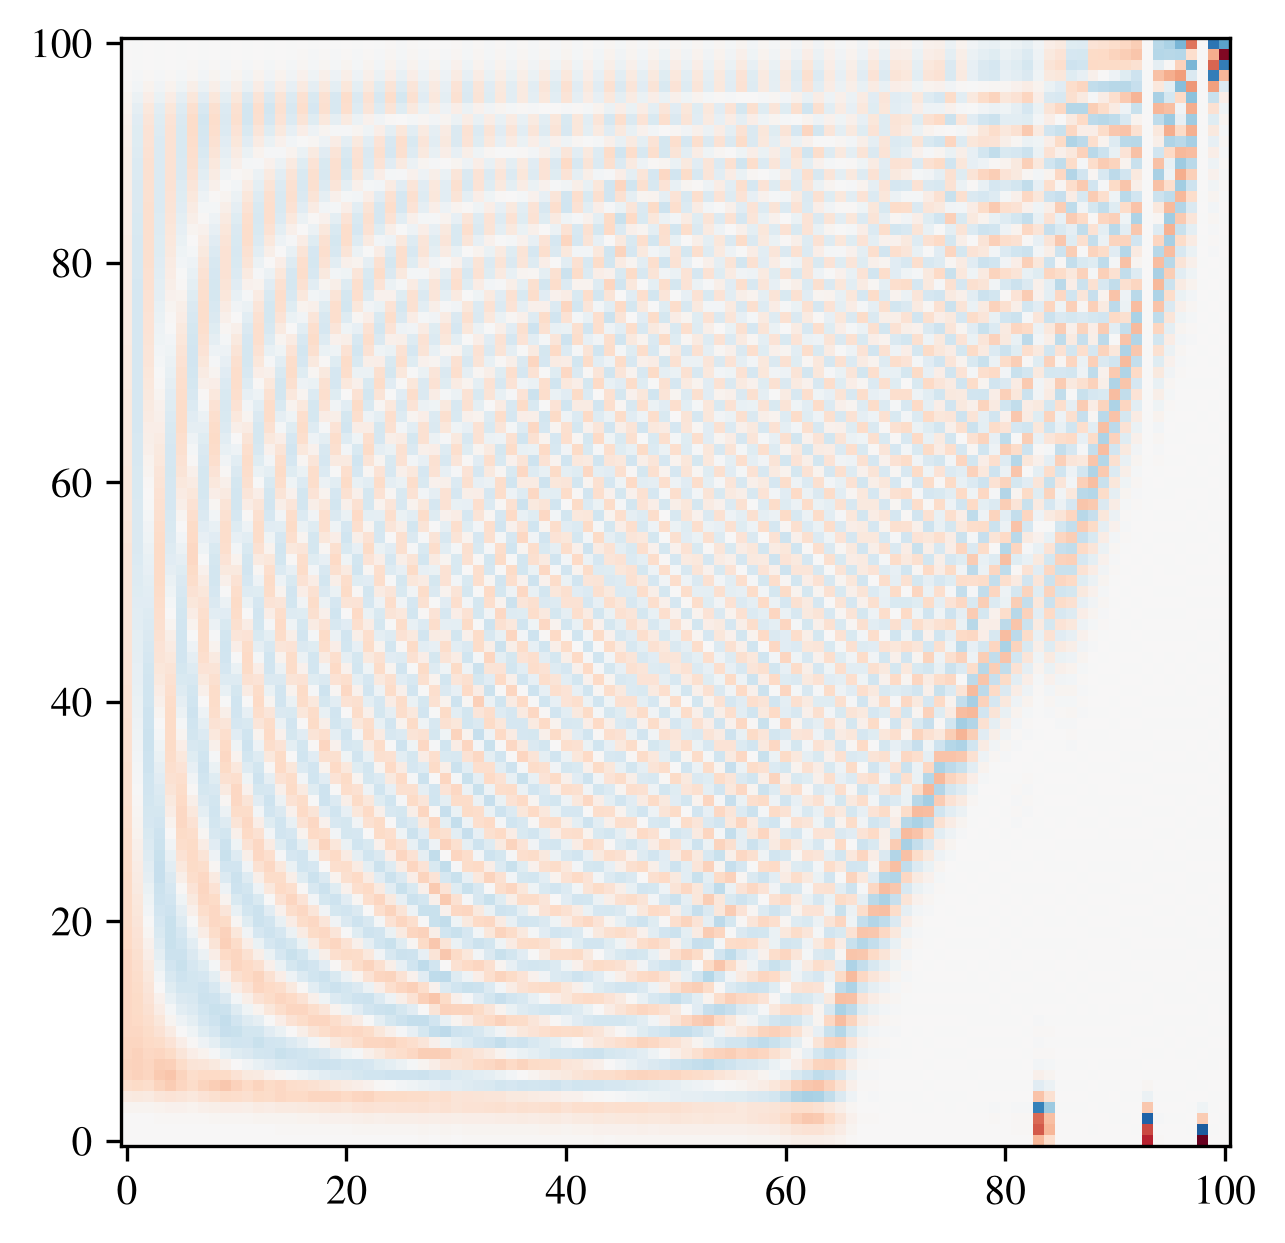

In [105]:
v = np.max(np.abs(eigvecs))
plt.imshow(eigvecs, cmap='RdBu_r', vmin=-v, vmax=v)
plt.show()

25
9


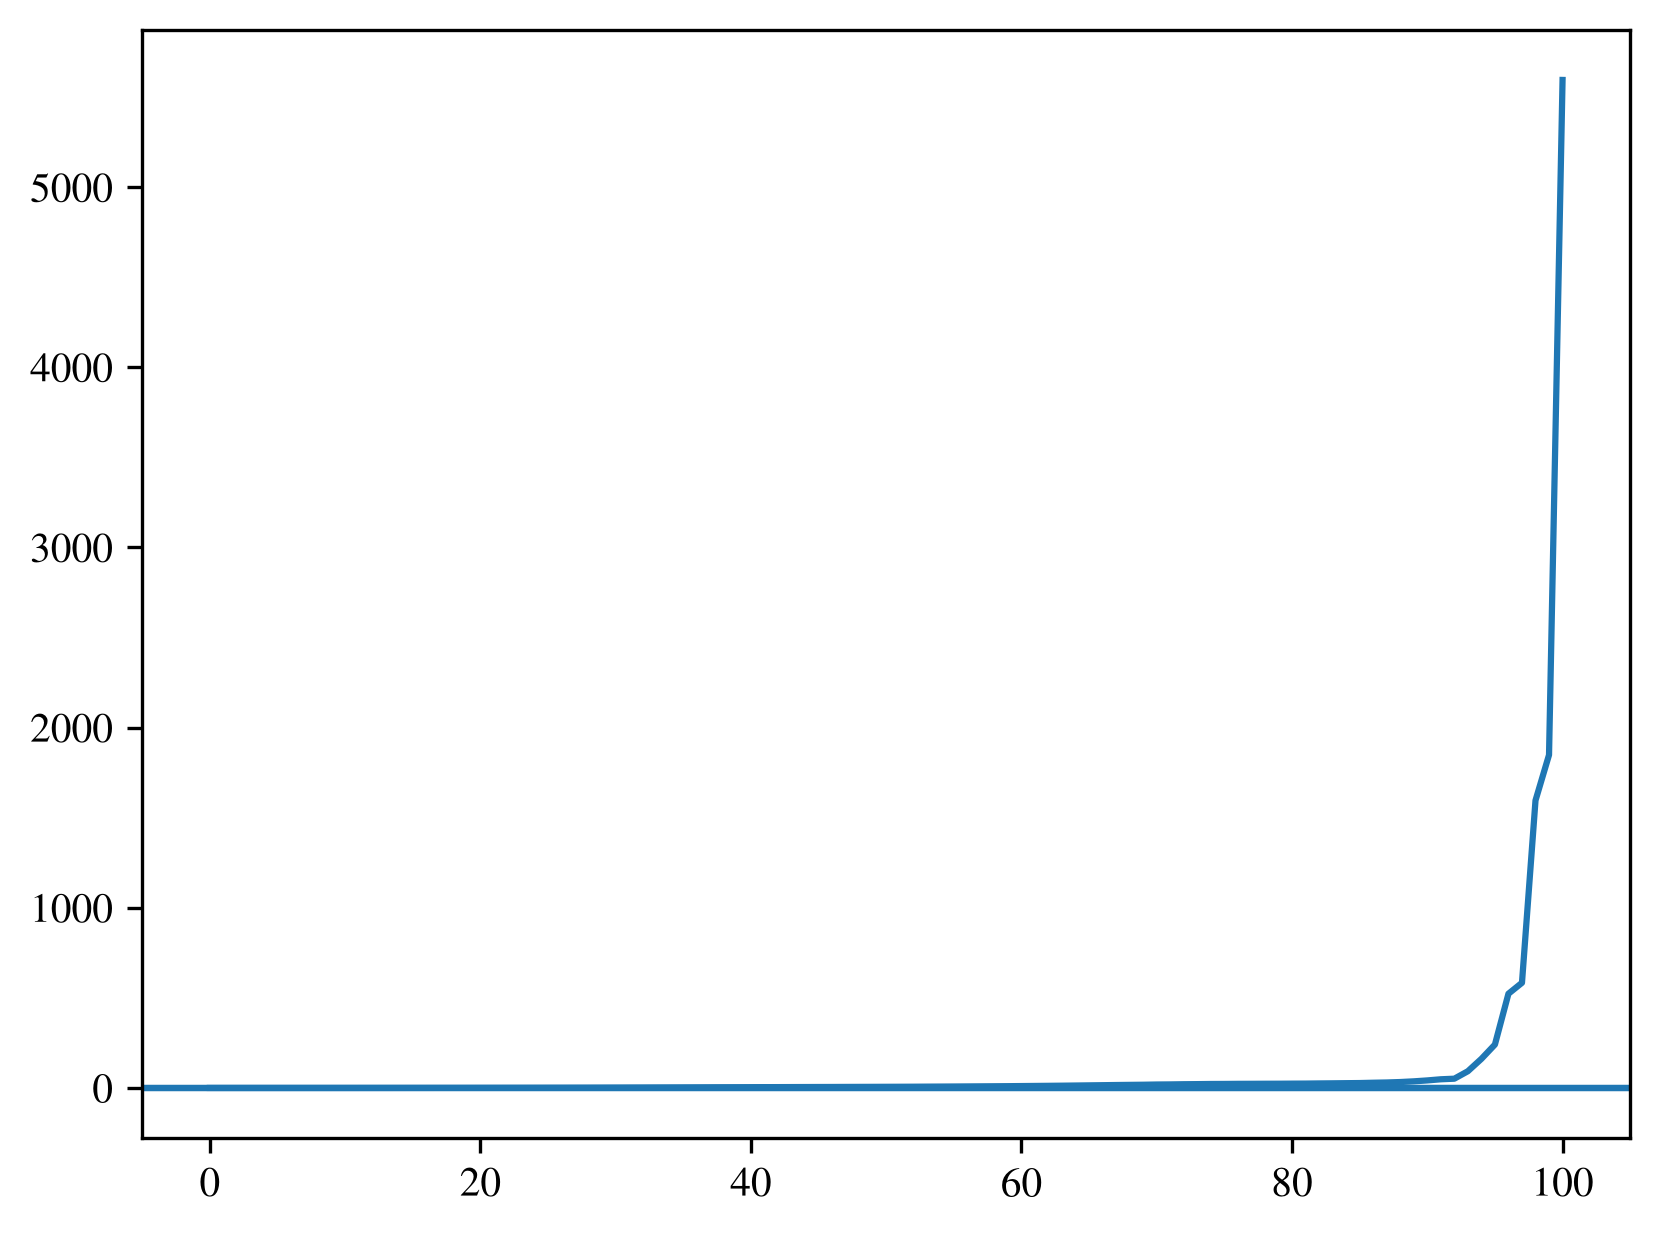

In [74]:
print(np.argmax(relstd>1.0))
print(np.argmax(relstd>0.1))
plt.plot(relstd[:101
                ])
plt.axhline(1.0)
plt.axhline(0.1)
plt.show()


In [ ]:
# I mean f200lp can be done... it just a question of whether you want to...